# 07 · MOS dataset
Builds the singing-quality dataset from SingMOS-Pro and MAST melody. CPU runtime is enough.

- The train/val/test split is made *before* augmentation and is **grouped**, so no group is in more than one split.
  - SingMOS-Pro: group = `dataset + raw_wav_id` (the same source song segment rendered by different systems stays together).
  - MAST: group = melody (`52_mel2`, 39 groups). MAST has no singer IDs.
  - Augmented clips are only created from train clips, so val/test contain only original, unaugmented recordings.
- All MAST performance recordings are used. MAST grades (1–4 scale) are mapped linearly to 1–5. The target keeps its
  original precision; 0.5 bins are only used for stratification and balancing.
- All random steps are seeded.

Before running: put `MAST_melody_audio.zip` and `annotations.csv` (from `to_colab/`) into `MyDrive/szakdolgozat/`.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os, glob, json, shutil, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import librosa, soundfile as sf
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

SINGMOS_ZIP = "/content/drive/MyDrive/SingMOS/SingMOS-Pro.zip"
MAST_ZIP = "/content/drive/MyDrive/szakdolgozat/MAST_melody_audio.zip"
MAST_CSV = "/content/drive/MyDrive/szakdolgozat/annotations.csv"
OUT = "/content/drive/MyDrive/szakdolgozat/v2"
RES = f"{OUT}/results"
AUDIO = "/content/mos_audio"          # every clip, 16 kHz mono wav
SEED = 42
SR = 16000
CAP, FLOOR = 700, 350                 # per 0.5-bin limits, applied to the TRAIN split only
os.makedirs(RES, exist_ok=True); os.makedirs(AUDIO, exist_ok=True)

In [3]:
for z, d in [(SINGMOS_ZIP, "/content/SingMOS"), (MAST_ZIP, "/content/MAST")]:
    if not os.path.exists(d):
        with zipfile.ZipFile(z) as f:
            f.extractall(d)
SM_ROOT = os.path.dirname(glob.glob("/content/SingMOS/**/metadata.json", recursive=True)[0])
MAST_DIR = os.path.dirname(glob.glob("/content/MAST/**/*.m4a", recursive=True)[0])
print(SM_ROOT, MAST_DIR)

/content/SingMOS/SingMOS-Pro /content/MAST/MAST_melody_audio


## SingMOS-Pro
`metadata.json` has the per-judge scores plus `type` (gt = real recording; svs/svc/svr = synthesized/converted),
`system_id` and `raw_wav_id`.

In [4]:
meta = json.load(open(f"{SM_ROOT}/metadata.json", encoding="utf8"))
sm = pd.DataFrame({
    "src_path": [f"{SM_ROOT}/{m['wav']}" for m in meta],
    "wav": [os.path.basename(m["wav"]) for m in meta],
    "mos": [np.mean(m["judge_score"]) for m in meta],
    "source": "singmos",
    "subtype": [m["type"] for m in meta],
    "system": [m["system_id"] for m in meta],
    "group": [f"sm:{m['dataset']}:{m['raw_wav_id']}" for m in meta],
})
assert sm.mos.between(1, 5).all()
print(len(sm), "clips,", sm.group.nunique(), "groups"); sm.subtype.value_counts()

7981 clips, 1735 groups


,count
subtype,
svs,3425
svr,2671
svc,1307
gt,578


## MAST melody
Three experts graded each performance on a **1–4** scale; two of them annotated the collection twice, giving five grades
per recording. Mean grade → `1 + (g − 1) · 4/3` puts it on the 1–5 MOS range.
Only candidate performances (`_per`) are used; `_ref` files are the reference melodies.

In [5]:
mast = pd.read_csv(MAST_CSV)
mast = mast[mast["file"].str.contains("_per")]
raters = ["1Asli", "5Ozan", "2Asli", "3Cihan", "4Cihan"]
# 5 files are listed twice with their ratings split across the two rows -> merge per file
mast = mast.groupby("file", as_index=False)[raters].mean()
grade = mast[raters].mean(axis=1)
mast = pd.DataFrame({
    "src_path": MAST_DIR + "/" + mast["file"].str.replace(".wav", ".m4a", regex=False),
    "wav": "mast_" + mast["file"],
    "mos": 1 + (grade - 1) * 4 / 3,
    "source": "mast",
    "subtype": "human",
    "system": "mast",
    "group": "mast:" + mast["file"].str.extract(r"^(\d+_mel\d+)")[0],
})
assert mast.group.notna().all() and mast.mos.between(1, 5).all()
print(len(mast), "clips,", mast.group.nunique(), "groups")

1041 clips, 39 groups


In [6]:
df = pd.concat([sm, mast], ignore_index=True)
df["mos_bin"] = (df["mos"] * 2).round() / 2
df["is_aug"] = False
df["orig_wav"] = df["wav"]
pd.crosstab(df.mos_bin, df.source, margins=True)

source,mast,singmos,All
mos_bin,,,
1.0,197,70,267
1.5,190,30,220
2.0,136,239,375
2.5,94,361,455
3.0,71,1901,1972
3.5,36,1317,1353
4.0,36,2452,2488
4.5,88,697,785
5.0,193,914,1107


## Resample everything to 16 kHz mono wav

In [7]:
for src, wav in tqdm(list(zip(df.src_path, df.wav))):
    out = f"{AUDIO}/{wav}"
    if not os.path.exists(out):
        y, _ = librosa.load(src, sr=SR, mono=True)
        sf.write(out, y, SR)

  0%|          | 0/9022 [00:00<?, ?it/s]

## Grouped, stratified split (~72 / 14 / 14)
Stratified on source × MOS bin so both sources and all score levels appear in every split.

In [8]:
def group_split(d, n_splits, seed=SEED):
    strat = d["source"] + "_" + d["mos_bin"].astype(str)
    rest, held = next(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(d, strat, d["group"]))
    return d.iloc[rest], d.iloc[held]

trainval, test = group_split(df, 7)
train, val = group_split(trainval, 6)
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"
assert df.groupby("group").split.nunique().max() == 1, "a group crosses splits"
pd.crosstab(df.split, df.source, margins=True)

source,mast,singmos,All
split,,,
test,95,1099,1194
train,852,5660,6512
val,94,1222,1316
All,1041,7981,9022


## Balance the TRAIN split only
Bins above `CAP` are randomly downsampled. Bins below `FLOOR` get augmented copies
(pitch shift ±1 semitone, time stretch 0.98-1.02), at most one per original clip on average.
Val and test are left untouched (natural distribution, no augmentation).

In [9]:
def augment(src, dst, rng):
    y, sr = librosa.load(src, sr=None)
    y = librosa.effects.pitch_shift(y=y, sr=sr, n_steps=rng.uniform(-1, 1))
    y = librosa.effects.time_stretch(y=y, rate=rng.uniform(0.98, 1.02))
    sf.write(dst, y, sr)

rng = np.random.default_rng(SEED)
train_parts, aug_rows = [], []
for b, g in df[df.split == "train"].groupby("mos_bin"):
    train_parts.append(g.sample(min(len(g), CAP), random_state=SEED))
    need = min(max(FLOOR - len(g), 0), len(g))
    for i, r in enumerate(g.sample(need, replace=True, random_state=SEED).to_dict("records")):
        r["wav"] = r["orig_wav"].replace(".wav", f"_aug{i}.wav")
        r["is_aug"] = True
        augment(f"{AUDIO}/{r['orig_wav']}", f"{AUDIO}/{r['wav']}", rng)
        aug_rows.append(r)

final = pd.concat([*train_parts, pd.DataFrame(aug_rows), df[df.split != "train"]], ignore_index=True)
final = final.drop(columns="src_path")
print("before balancing:", len(df), " after:", len(final), " augmented:", len(aug_rows))
pd.crosstab(final.mos_bin, final.split, margins=True)

before balancing: 9022  after: 7257  augmented: 397


split,test,train,val,All
mos_bin,,,,
1.0,29,350,26,405
1.5,27,334,26,387
2.0,46,350,57,453
2.5,52,350,67,469
3.0,266,700,282,1248
3.5,186,700,208,1094
4.0,335,700,358,1393
4.5,101,563,121,785
5.0,152,700,171,1023


## Dataset partitions: table and figure

source        mast  singmos   All
split is_aug                     
test  False     95     1099  1194
train False    780     3570  4350
      True     279      118   397
val   False     94     1222  1316
All           1248     6009  7257


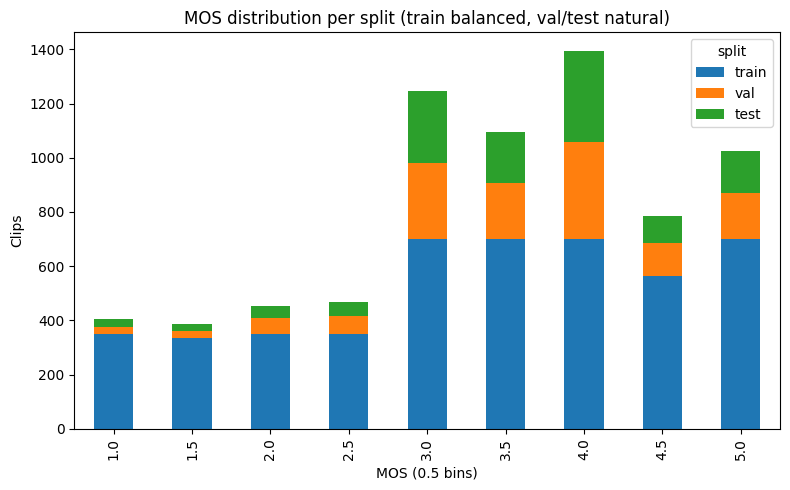

In [10]:
t1 = pd.crosstab([final.split, final.is_aug], final.source, margins=True)
t1.to_csv(f"{RES}/table1_mos_splits.csv"); print(t1)
pd.crosstab(final.mos_bin, final.split).to_csv(f"{RES}/mos_bins_by_split.csv")

ct = pd.crosstab(final.mos_bin, [final.split])[["train", "val", "test"]]
ct.plot.bar(stacked=True, figsize=(8, 5), xlabel="MOS (0.5 bins)", ylabel="Clips",
            title="MOS distribution per split (train balanced, val/test natural)")
plt.tight_layout(); plt.savefig(f"{RES}/fig1_mos_distribution.png", dpi=200); plt.show()

In [11]:
final.to_csv(f"{OUT}/mos_metadata.csv", index=False)
keep = set(final.wav)
for f in os.listdir(AUDIO):          # drop clips removed by the cap so the zip only holds used audio
    if f not in keep:
        os.remove(f"{AUDIO}/{f}")
shutil.make_archive(f"{OUT}/mos_audio", "zip", AUDIO)   # -> v2/mos_audio.zip
print("saved", len(final), "rows and", len(os.listdir(AUDIO)), "wavs")

saved 7257 rows and 7257 wavs
